In [1]:
import os
CUDA_LAUNCH_BLOCKING=1
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64,garbage_collection_threshold:0.6"

import sys
import re
import numpy as np
import pandas as pd
from pathlib import Path
import logging

import torch
import torch.nn as nn
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
sys.path.append(str(PROJECT_DIR))

from scripts.train_tf_to_dna_model import TFPeakEdgeDataset
import utils

DATA_DIR = PROJECT_DIR.parent / "data"
CHKPT_DIR = PROJECT_DIR / "checkpoints"

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

In [43]:
original_model_df = pd.read_csv(PROJECT_DIR / "new_plots/prediction_landscapes/plotly_tf_dna_landscape_mm10_all_tfs_summary_original.tsv", sep="\t")
new_model_df = pd.read_csv(PROJECT_DIR / "new_plots/prediction_landscapes/plotly_tf_dna_landscape_mm10_3924586_epoch14_all_tfs_summary.tsv", sep="\t")

In [47]:
original_model_df.columns

Index(['tf_name', 'family', 'motif_id', 'motif_status', 'motif_len',
       'consensus', 'p_background', 'p_one_copy', 'p_max_copies',
       'one_copy_effect', 'ref_bound_mean', 'ref_unbound_mean', 'n_bound',
       'n_unbound'],
      dtype='object')

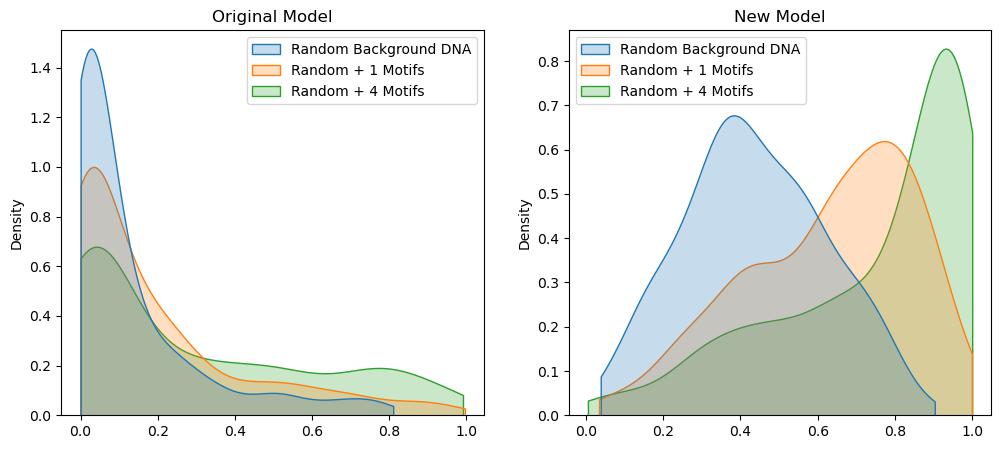

In [203]:
new_labels = {
    "p_background": "Random Background DNA",
    "p_one_copy": "Random + 1 Motifs",
    "p_max_copies": "Random + 4 Motifs"
}

original_model_df.rename(columns=new_labels, inplace=True)
new_model_df.rename(columns=new_labels, inplace=True)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
sns.kdeplot(original_model_df[new_labels.values()], ax=axes[0], fill=True, cut=0)

axes[0].set_title("Original Model")

sns.kdeplot(new_model_df[list(new_labels.values())], ax=axes[1], fill=True, cut=0)
axes[1].set_title("New Model")

plt.savefig(PROJECT_DIR / "new_plots" / "tf_dna_binding_evaluation" / "tf_motif_binding_kde.png", dpi=300, bbox_inches="tight")

In [89]:
new_model_df["Random Background DNA"].std()

np.float64(0.18560913366075965)

### Plotting and Helper Functions

In [2]:
def detach(tensor):
    if isinstance(tensor, torch.Tensor):
        return tensor.detach().cpu().numpy()
    else:
        return tensor


def unmask(tensor, mask):
    if isinstance(tensor, torch.Tensor) and isinstance(mask, torch.Tensor):
        return tensor[mask == 1]
    else:
        raise ValueError("Both tensor and mask must be torch.Tensor instances.")


def plot_single_row_heatmap(values, col_values, title):
    fig, ax = plt.subplots(figsize=(6, 0.5))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()

    im = ax.imshow(
        values_plotting.T,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(col_values) - 1, 9, dtype=int)
    ax.set_xticks(tick_positions)

    tick_labels = [f"{col_values[i]:.1f}" for i in tick_positions]
    ax.set_xlabel("Expression Input", fontsize=14, labelpad=10)

    ax.set_xticklabels(tick_labels, fontsize=12)
    ax.set_yticklabels(["1"], fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()
    
    
def plot_single_column_heatmap(values, row_values, title):
    fig, ax = plt.subplots(figsize=(1, 8))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()
        
    im = ax.imshow(
        values_plotting,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(row_values) - 1, 9, dtype=int)
    ax.set_yticks(tick_positions)

    tick_labels = [f"{row_values[i]:.1f}" for i in tick_positions]
    ax.set_ylabel("Projection dimension", fontsize=14, labelpad=10)

    ax.set_yticklabels(tick_labels, fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=False, labeltop=False, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()


def plot_projected_expression(
    projection_dict,
    keep_square=False,
    height=8,
    ncols=3,
    xlabel=None,
    ylabel=None,
    cmap="viridis",
):
    if not projection_dict:
        raise ValueError("projection_dict must not be empty")

    # Prepare matrices without modifying the original dictionary.
    prepared = []
    for title, (projected, inputs) in projection_dict.items():
        if projected.ndim == 3 and projected.shape[0] == 1:
            projected = projected.squeeze(0)

        if projected.ndim != 2:
            raise ValueError(
                f"{title}: expected a 2D projection or a singleton batch, "
                f"got shape {tuple(projected.shape)}"
            )

        if any(size == 0 for size in projected.shape):
            raise ValueError(f"{title}: projection dimensions must be nonzero")

        prepared.append((title, projected.T, inputs))

    # Number of subplot columns and rows
    if ncols < 1:
        raise ValueError("ncols must be positive")

    ncols = min(int(ncols), len(prepared))
    nrows = (len(prepared) + ncols - 1) // ncols

    # Physical cell dimensions, in inches
    cell_width = 0.15
    cell_height = 0.15

    # Margins and spacing, in inches
    left, right = 1.0, 0.3
    bottom, top = 0.8, 1.2
    hgap = 1.0
    vgap = 1.5  # Room for titles and x-axis labels between rows

    shapes = [matrix.shape for _, matrix, _ in prepared]

    # Each layout column/row accommodates its largest heatmap.
    column_widths = [
        max(
            shapes[i][1] * cell_width
            for i in range(col, len(prepared), ncols)
        )
        for col in range(ncols)
    ]

    row_heights = [
        max(
            shapes[i][0] * cell_height
            for i in range(row * ncols, min((row + 1) * ncols, len(prepared)))
        )
        for row in range(nrows)
    ]

    # Scale all heatmap cells uniformly to fit the total height limit.
    fixed_height = bottom + top + vgap * (nrows - 1)
    if height <= fixed_height:
        raise ValueError(
            f"height must exceed {fixed_height:.1f} inches "
            "to accommodate margins and spacing; increase height or ncols"
        )

    scale = min(1.0, (height - fixed_height) / sum(row_heights))
    
    title_fontsize = max(6, 16 * scale)
    label_fontsize = max(6, 14 * scale)
    tick_fontsize = max(5, 12 * scale)

    column_widths = [width * scale for width in column_widths]
    row_heights = [row_height * scale for row_height in row_heights]

    plot_widths = [cols * cell_width * scale for rows, cols in shapes]
    plot_heights = [rows * cell_height * scale for rows, cols in shapes]

    fig_width = left + sum(column_widths) + hgap * (ncols - 1) + right
    fig_height = fixed_height + sum(row_heights)

    fig = plt.figure(figsize=(fig_width, fig_height))
    axes = []

    row_top = fig_height - top

    for row in range(nrows):
        x = left

        for col in range(ncols):
            i = row * ncols + col
            if i >= len(prepared):
                break

            plot_width = plot_widths[i]
            plot_height = plot_heights[i]

            ax = fig.add_axes([
                x / fig_width,
                (row_top - plot_height) / fig_height,
                plot_width / fig_width,
                plot_height / fig_height,
            ])
            axes.append(ax)

            x += column_widths[col] + hgap

        row_top -= row_heights[row] + vgap

    for ax, (title, matrix, inputs), plot_height in zip(
        axes, prepared, plot_heights
    ):
        ax.imshow(
            matrix,
            aspect="equal" if keep_square else "auto",
            interpolation="nearest",
            cmap=cmap,
        )

        if inputs is not None and len(inputs) > 0:
            tick_positions = np.unique(
                np.linspace(0, len(inputs) - 1, 9, dtype=int)
            )
            ax.set_xticks(tick_positions)
            ax.set_xticklabels(
                [f"{inputs[j]:.1f}" for j in tick_positions],
                fontsize=tick_fontsize,
            )
            ax.set_xlabel(
                xlabel if xlabel is not None else "Expression Input",
                fontsize=label_fontsize,
                labelpad=10,
            )
            ax.tick_params(
                axis="x",
                top=True,
                labeltop=True,
                bottom=False,
                labelbottom=False,
            )
        else:
            ax.set_xticks([])
            if xlabel is not None:
                ax.set_xlabel(xlabel, fontsize=label_fontsize, labelpad=10)

        ax.tick_params(axis="y", labelsize=tick_fontsize)
        
        label = ylabel if ylabel is not None else "Projection size"

        # Remove existing newlines, then wrap only for short heatmaps.
        label = " ".join(label.split())

        if plot_height < 1.5:
            label = label.replace(" ", "\n")

        ax.set_ylabel(label, fontsize=label_fontsize, wrap=False)
                
        
        ax.set_title(title, fontsize=title_fontsize, pad=10)
        ax.xaxis.set_label_position("top")

    plt.show()

### Loading the TF-DNA binding model and inputs

In [69]:
species = "mm10"

mm10_tf_dna_path = CHKPT_DIR / "tf_dna_mm10_3924586" / "epoch_14.ckpt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tf_dna_input_cache_dir = PROJECT_DIR / "cached_data" / species / "tf_dna_cache_bkp"

tf_dna_data = utils.load_tf_dna_data(tf_dna_input_cache_dir)

# Unpack all returned tensors
edge_tf_idx_tensor, edge_peak_idx_tensor, edge_labels_tensor, \
    tf_embeddings_tensor, tf_mask_tensor, one_hot_peaks = tf_dna_data

# Name to ID dictionaries
tf_name_to_idx_df = pd.read_csv(tf_dna_input_cache_dir / "tf_name_to_idx.csv")
peak_id_to_idx_df = pd.read_csv(tf_dna_input_cache_dir / "peak_id_to_idx.csv")

tf_name_to_idx_dict = tf_name_to_idx_df.set_index("tf_name")["tf_idx"].to_dict()
peak_name_to_idx_dict = peak_id_to_idx_df.set_index("peak_id")["peak_idx"].to_dict()

tf_idx_to_name = {idx: name for name, idx in tf_name_to_idx_dict.items()}
peak_idx_to_name = {idx: name for name, idx in peak_name_to_idx_dict.items()}

# Load the trained TF-DNA model
tf_dna_model = utils.load_tf_dna_model(
    tf_dna_model_path=mm10_tf_dna_path,
    tf_embeddings_tensor=tf_embeddings_tensor,
    tf_mask_tensor=tf_mask_tensor,
    device=device,
)
tf_dna_model

LitTFPeakBindingModel(
  (model): TFPeakBindingModel(
    (tf_encoder): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=128, out_features=128, bias=True)
    )
    (peak_encoder): Sequential(
      (0): Conv1d(4, 64, kernel_size=(15,), stride=(1,), padding=(7,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): GELU(approximate='none')
      (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (4): Conv1d(64, 128, kernel_size=(9,), stride=(1,), padding=(4,))
      (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): GELU(approximate='none')
      (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (8): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (9): BatchNorm1d(128, ep

In [4]:
dataset = TFPeakEdgeDataset(
    edge_tf_idx=edge_tf_idx_tensor,
    edge_peak_idx=edge_peak_idx_tensor,
    edge_labels=edge_labels_tensor,
    peak_tensor=one_hot_peaks
)

item = dataset[0]
item

{'tf_idx': tensor(58),
 'peak_idx': tensor(3209599),
 'peak_embedding': tensor([[0, 0, 0, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         ...,
         [0, 0, 0, 1],
         [0, 0, 0, 1],
         [0, 0, 0, 1]], dtype=torch.uint8),
 'label': tensor(0.)}

### Run a model prediction

In [6]:
parameter = next(tf_dna_model.parameters())
device = parameter.device
dtype = parameter.dtype

for i in range(15):
    tf_embedding = tf_embeddings_tensor[dataset[i]["tf_idx"]].unsqueeze(0).to(device=device, dtype=dtype)
    tf_mask = tf_mask_tensor[dataset[i]["tf_idx"]].unsqueeze(0).to(device=device, dtype=torch.bool)
    peak_onehot = one_hot_peaks[dataset[i]["peak_idx"]].unsqueeze(0).to(device=device, dtype=dtype)

    tf_dna_model.eval()

    with torch.no_grad():
        output_logit = tf_dna_model(tf_embedding, tf_mask, peak_onehot)
        output_prob = torch.sigmoid(output_logit)

    if output_prob > 0.5:
        print(f"Iteration {i}: TF {dataset[i]['tf_idx']} binds to peak {dataset[i]['peak_idx']} with probability {output_prob.item():.4f}")


Iteration 2: TF 57 binds to peak 6824660 with probability 0.9026
Iteration 4: TF 194 binds to peak 1463383 with probability 0.9499
Iteration 5: TF 351 binds to peak 2861859 with probability 0.6342
Iteration 8: TF 157 binds to peak 1731277 with probability 0.5025
Iteration 9: TF 234 binds to peak 3696083 with probability 0.5829
Iteration 11: TF 245 binds to peak 2765605 with probability 0.9955


### TF embedding and peak-onehot tensor structure

In [33]:
len(edge_tf_idx_tensor.unique())

443

--- General Information ---
  - Number of Edges: 9,299,874
     - True edges: 1,549,979
     - False edges: 7,749,895
  - Number of TFs: 443
  - Number of DNA Sites: 9,032,432


--- Edge TF and DNA Indices ---
Edge TF index tensor torch.Size([9299874])
  - First Edge's TF index: 58
  - First Edge's TF name: Batf3

Edge peak index tensor torch.Size([9299874])
  - First Edge's peak index: 3209599
  - First Edge's DNA location: chr17:63422173-63422426


--- TF Embedding and Mask Tensors ---
TF embedding tensor (torch.Size([443, 5588, 128]))
  - Number of Batches: 443
  - Largest TF length: 5,588
  - Embedding dimension: 128

TF padding mask tensor (torch.Size([443, 5588]))
  - Number of Batches: 443
  - Largest TF length: 5,588

TF padding mask for the first TF (torch.Size([5588]))
  - 118 valid positions (1s)
  - 5,352 padded positions (0s)


--- One-hot Peak Tensor ---
One-hot peak tensor (shape: torch.Size([9032432, 256, 4])):
  - Number of Peaks: 9032432
  - Peak length: 256
  - One-h

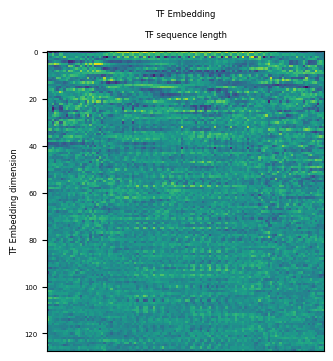

In [87]:
print(f"--- General Information ---")
print(f"  - Number of Edges: {len(edge_tf_idx_tensor):,}")
print(f"     - True edges: {len(torch.where(edge_labels_tensor == 1)[0]):,}")
print(f"     - False edges: {len(torch.where(edge_labels_tensor == 0)[0]):,}")
print(f"  - Number of TFs: {len(edge_tf_idx_tensor.unique()):,}")
print(f"  - Number of DNA Sites: {len(edge_peak_idx_tensor.unique()):,}")

print("\n\n--- Edge TF and DNA Indices ---")
print(f"Edge TF index tensor {edge_tf_idx_tensor.shape}")
print(f"  - First Edge's TF index: {edge_tf_idx_tensor[0]}")
print(f"  - First Edge's TF name: {tf_idx_to_name[edge_tf_idx_tensor[0].item()]}")

print(f"\nEdge peak index tensor {edge_peak_idx_tensor.shape}")
print(f"  - First Edge's peak index: {edge_peak_idx_tensor[0]}")
print(f"  - First Edge's DNA location: {peak_idx_to_name[edge_peak_idx_tensor[0].item()]}")

print("\n\n--- TF Embedding and Mask Tensors ---")
print(f"TF embedding tensor ({tf_embeddings_tensor.shape})")
print(f"  - Number of Batches: {tf_embeddings_tensor.shape[0]:,}")
print(f"  - Largest TF length: {tf_embeddings_tensor.shape[1]:,}")
print(f"  - Embedding dimension: {tf_embeddings_tensor.shape[2]:,}")

# print(tf_embeddings_tensor[edge_tf_idx_tensor[0], :5, :5])

print(f"\nTF padding mask tensor ({tf_mask_tensor.shape})")
print(f"  - Number of Batches: {tf_mask_tensor.shape[0]:,}")
print(f"  - Largest TF length: {tf_mask_tensor.shape[1]:,}")

mask = tf_mask_tensor[edge_tf_idx_tensor[0]]
num_mask_true_positions = len(torch.where(mask == 1)[0])
num_mask_false_positions = len(torch.where(mask == 0)[0]) - num_mask_true_positions
print(f"\nTF padding mask for the first TF ({mask.shape})")
print(f"  - {num_mask_true_positions:,} valid positions (1s)")
print(f"  - {num_mask_false_positions:,} padded positions (0s)")

print("\n\n--- One-hot Peak Tensor ---")
print(f"One-hot peak tensor (shape: {one_hot_peaks.shape}):")
print(f"  - Number of Peaks: {one_hot_peaks.shape[0]}")
print(f"  - Peak length: {one_hot_peaks.shape[1]}")
print(f"  - One-hot encoding dimension: {one_hot_peaks.shape[2]}")
first_peak_sequence = utils.get_peak_sequence(edge_peak_idx_tensor[0], one_hot_peaks)
print(f"  - First peak location: {peak_idx_to_name[edge_peak_idx_tensor[0].item()]}")
print(f"  - First peak sequence ({len(first_peak_sequence)} bp): {first_peak_sequence[:10]}...{first_peak_sequence[-10:]}")

unmasked_tf_tensor = tf_embeddings_tensor[edge_tf_idx_tensor[0]][mask]


tf_embedding_dict = {
    "TF Embedding": (unmasked_tf_tensor, None)
}
plot_projected_expression(
    tf_embedding_dict, 
    keep_square=False, 
    height=5, 
    xlabel="TF sequence length", 
    ylabel="TF Embedding dimension"
    )

In [ ]:
def generate_random_background_dna_sequence(background_nuc_freq: dict) -> str:
    """
    Generate a random DNA sequence based on specified nucleotide frequencies.

    Parameters:
    background_nuc_freq (dict): A dictionary with nucleotides as keys ('A', 'C', 'G', 'T') 
                                 and their corresponding frequencies as values.

    Returns:
    str: A randomly generated DNA sequence.
    """
    nucleotides = list(background_nuc_freq.keys())
    frequencies = list(background_nuc_freq.values())
    
    # Normalize frequencies to ensure they sum to 1
    total = sum(frequencies)
    normalized_frequencies = [freq / total for freq in frequencies]
    
    # Generate a random DNA sequence of length 256
    sequence_length = 256
    random_sequence = np.random.choice(nucleotides, size=sequence_length, p=normalized_frequencies)
    
    return ''.join(random_sequence)

mm10_bg = {
    'A': 0.2925, 
    'T': 0.2925, 
    'G': 0.2075, 
    'C': 0.2075
}

random_bg_sequence = generate_random_background_dna_sequence(mm10_bg)
print(f"Random Background DNA Sequence (length {len(random_bg_sequence)}): {random_bg_sequence[:50]}...{random_bg_sequence[-50:]}")




Random Background DNA Sequence (length 256): ATTAAATACTACTCCGCAGTGAAACCAGGCGATGGTAATTCTGTTAGCAG...GGGGAGGTTGCGTTGCTCGGATAGCTTGAACAACGATTCATATCAAATTG


/tmp/ipykernel_3399286/3977439804.py:35: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /opt/conda/conda-bld/pytorch_1729647327489/work/torch/csrc/utils/tensor_new.cpp:278.)
  random_bg_onehot = torch.tensor([utils.onehot_dna_sequence(generate_random_background_dna_sequence(mm10_bg)) for i in range(10)])
/tmp/ipykernel_3399286/3977439804.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(random_bg_onehot).shape


torch.Size([10, 256, 4])

### Evaluate TF-DNA binding to random DNA sequences

In [204]:
tf_dna_model.eval()
tf_dna_model.to(device)

num_rand_seqs = 100

# Generate random background DNA sequences and convert them to one-hot encoding
random_dna = torch.tensor(
    [utils.onehot_dna_sequence(generate_random_background_dna_sequence(mm10_bg)) for _ in range(num_rand_seqs)],
    device=device,
    dtype=dtype
    )

# Calculate each TF's binding probabilities to the random background DNA sequences
tf_random_binding_probs = {}
for tf_idx in range(tf_embeddings_tensor.shape[0]):
    # Expand the TF embedding and mask tensors to match the number of random DNA sequences
    tf_embedding = tf_embeddings_tensor[tf_idx].expand(num_rand_seqs, -1, -1).to(device=device, dtype=dtype)
    tf_mask = tf_mask_tensor[tf_idx].expand(num_rand_seqs, -1).to(device=device, dtype=torch.bool)

    with torch.no_grad():
        output_logits = tf_dna_model(tf_embedding, tf_mask, random_dna)
        output_probs = torch.sigmoid(output_logits)

    tf_random_binding_probs[tf_idx] = (output_probs.detach().cpu().numpy(), random_dna.shape[0])

print("\n\n--- Random Background DNA Binding Probabilities ---")
tf_random_binding_df = pd.DataFrame({
    "TF": [tf_idx_to_name[tf_idx] for tf_idx in tf_random_binding_probs.keys()],
    "binding_mean": [probs.mean() for probs, _ in tf_random_binding_probs.values()],
    "binding_std": [probs.std() for probs, _ in tf_random_binding_probs.values()],
    "num_sequences": [dna_count for _, dna_count in tf_random_binding_probs.values()]
})
tf_random_binding_df



--- Random Background DNA Binding Probabilities ---


,TF,binding_mean,binding_std,num_sequences
0,Arid5a,0.476784,0.219628,100
1,Arid3a,0.613180,0.276968,100
2,Mnt,0.676185,0.253960,100
3,Tfap2a,0.193330,0.182591,100
4,Tfap4,0.330416,0.228632,100
...,...,...,...,...
438,Nr3c1,0.410734,0.140466,100
439,Pou5f1,0.586721,0.181168,100
440,Rela,0.415020,0.141331,100
441,Spi1,0.132289,0.120686,100


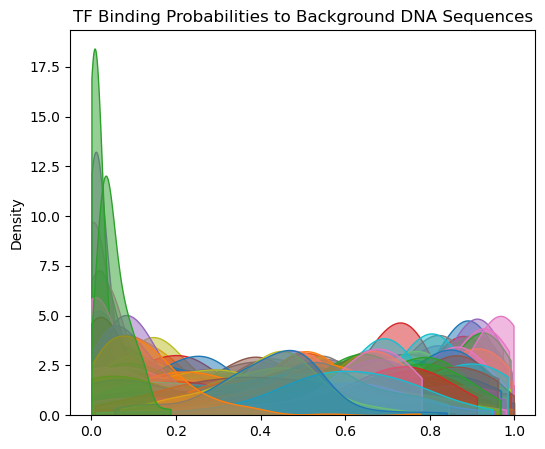

In [205]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6, 5))
for tf_idx in tf_random_binding_probs.keys():
    probs, _ = tf_random_binding_probs[tf_idx]
    sns.kdeplot(probs, ax=axes, fill=True, cut=0, label=tf_idx_to_name[tf_idx], alpha=0.5)

plt.title("TF Binding Probabilities to Background DNA Sequences")

plt.savefig(PROJECT_DIR / "new_plots" / "tf_dna_binding_evaluation" / "tf_random_dna_binding_kde.png", dpi=300, bbox_inches="tight")


Peak index tensor (shape: torch.Size([9299874])):
First peak index: 3209599

One-hot peak tensor (shape: torch.Size([9032432, 256, 4])):
  - Number of Peaks: 9032432
  - Peak length: 256
  - One-hot encoding dimension: 4



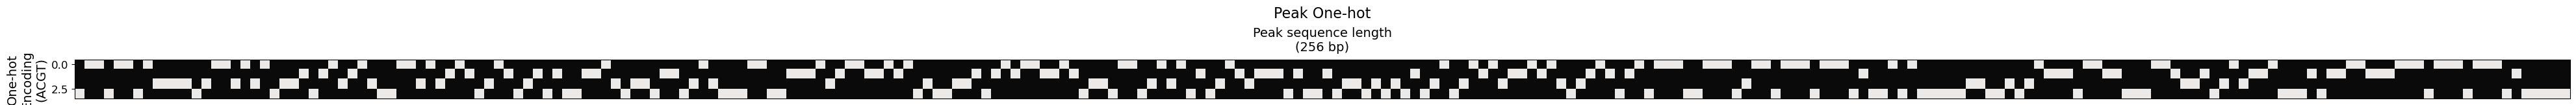

In [ ]:
import matplotlib.colors as mcolors

first_peak_onehot = one_hot_peaks[edge_peak_idx_tensor[0]]
peak_dict = {
    "Peak One-hot": (first_peak_onehot, None),
}

colors = ["#0A0A0A", "#ECE9E9"]

# Create a continuous colormap
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_2_color", colors
)

plot_projected_expression(
    peak_dict, 
    keep_square=False, 
    height=3,
    xlabel=f"Peak sequence length\n({first_peak_onehot.shape[0]} bp)",
    ylabel="One-hot\nEncoding\n(ACGT)",
    cmap=custom_cmap
    )



### TF Dense Layer

In [9]:
import torch.nn as nn

tf_input = tf_embeddings_tensor[edge_tf_idx_tensor[0]].unsqueeze(0)
m = tf_mask_tensor[edge_tf_idx_tensor[0]].unsqueeze(0)

tf_encoder_linear1 = tf_dna_model.model.tf_encoder[0](tf_input)
tf_encoder_gelu = tf_dna_model.model.tf_encoder[1](tf_encoder_linear1)
tf_encoder_dropout = tf_dna_model.model.tf_encoder[2](tf_encoder_gelu)
tf_encoder_linear2 = tf_dna_model.model.tf_encoder[3](tf_encoder_dropout)

tf_encoder_output_dict = {
    "TF embedding input": (detach(unmask(tf_input, m)), None),
    "Linear1 Output": (detach(unmask(tf_encoder_linear1, m)), None),
    "GELU Output": (detach(unmask(tf_encoder_gelu, m)), None),
    "Dropout Output": (detach(unmask(tf_encoder_dropout, m)), None),
    "Linear2 Output": (detach(unmask(tf_encoder_linear2, m)), None),
}
    
for key, (values, _) in tf_encoder_output_dict.items():
    print(f"{key}: shape {values.shape}")

TF embedding input: shape (118, 128)
Linear1 Output: shape (118, 128)
GELU Output: shape (118, 128)
Dropout Output: shape (118, 128)
Linear2 Output: shape (118, 128)


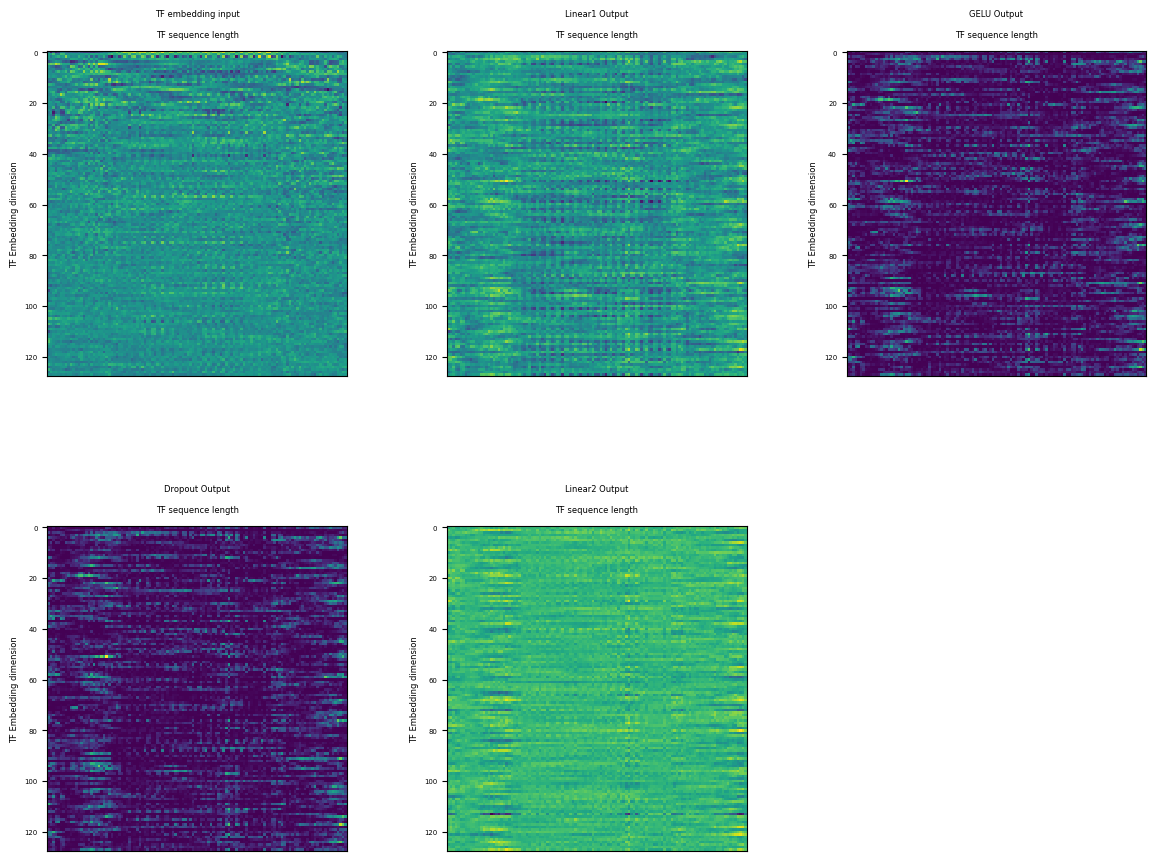

In [10]:
plot_projected_expression(
    tf_encoder_output_dict,
    keep_square=False,
    height=10,
    xlabel="TF sequence length",
    ylabel="TF Embedding dimension"
)

### Peak Encoder

In [11]:
peak_input = one_hot_peaks[edge_peak_idx_tensor[0]].unsqueeze(0).swapaxes(1, 2)
peak_input.to(dtype=torch.float32)
peak_input.shape

torch.Size([1, 4, 256])

In [12]:
layer = tf_dna_model.model.peak_encoder[0]

peak_input = peak_input.to(
    dtype=layer.weight.dtype,
    device=layer.weight.device,
)

peak_layer_dict = {"Peak Input": (peak_input.squeeze(0), None)}
peak_encoder_output = None
for i in range(len(tf_dna_model.model.peak_encoder)):
    layer = tf_dna_model.model.peak_encoder[i]
    
    if i == 0:
        input = peak_input
    else:
        previous_layer_output = peak_layer_dict[f"{layer_type}_{i-1}"][0]
        input = previous_layer_output
        
    layer_output = layer(input)
    layer_type = layer.__class__.__name__
    
    peak_layer_dict[f"{layer_type}_{i}"] = (layer_output, None)
    
    print(f"{layer_type}_{i}")
    print(f"  input shape: {input.shape}")
    print(f"  output shape: {layer_output.shape}")
    
    if i == len(tf_dna_model.model.peak_encoder) - 1:
        peak_encoder_output = layer_output
    
# Detach all tensors in peak_layer_dict
for key in peak_layer_dict:
    peak_layer_dict[key] = (detach(peak_layer_dict[key][0]), peak_layer_dict[key][1])


Conv1d_0
  input shape: torch.Size([1, 4, 256])
  output shape: torch.Size([1, 64, 256])
BatchNorm1d_1
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
GELU_2
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
MaxPool1d_3
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 64])
Conv1d_4
  input shape: torch.Size([1, 64, 64])
  output shape: torch.Size([1, 128, 64])
BatchNorm1d_5
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
GELU_6
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
MaxPool1d_7
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 16])
Conv1d_8
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
BatchNorm1d_9
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
GELU_10
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16

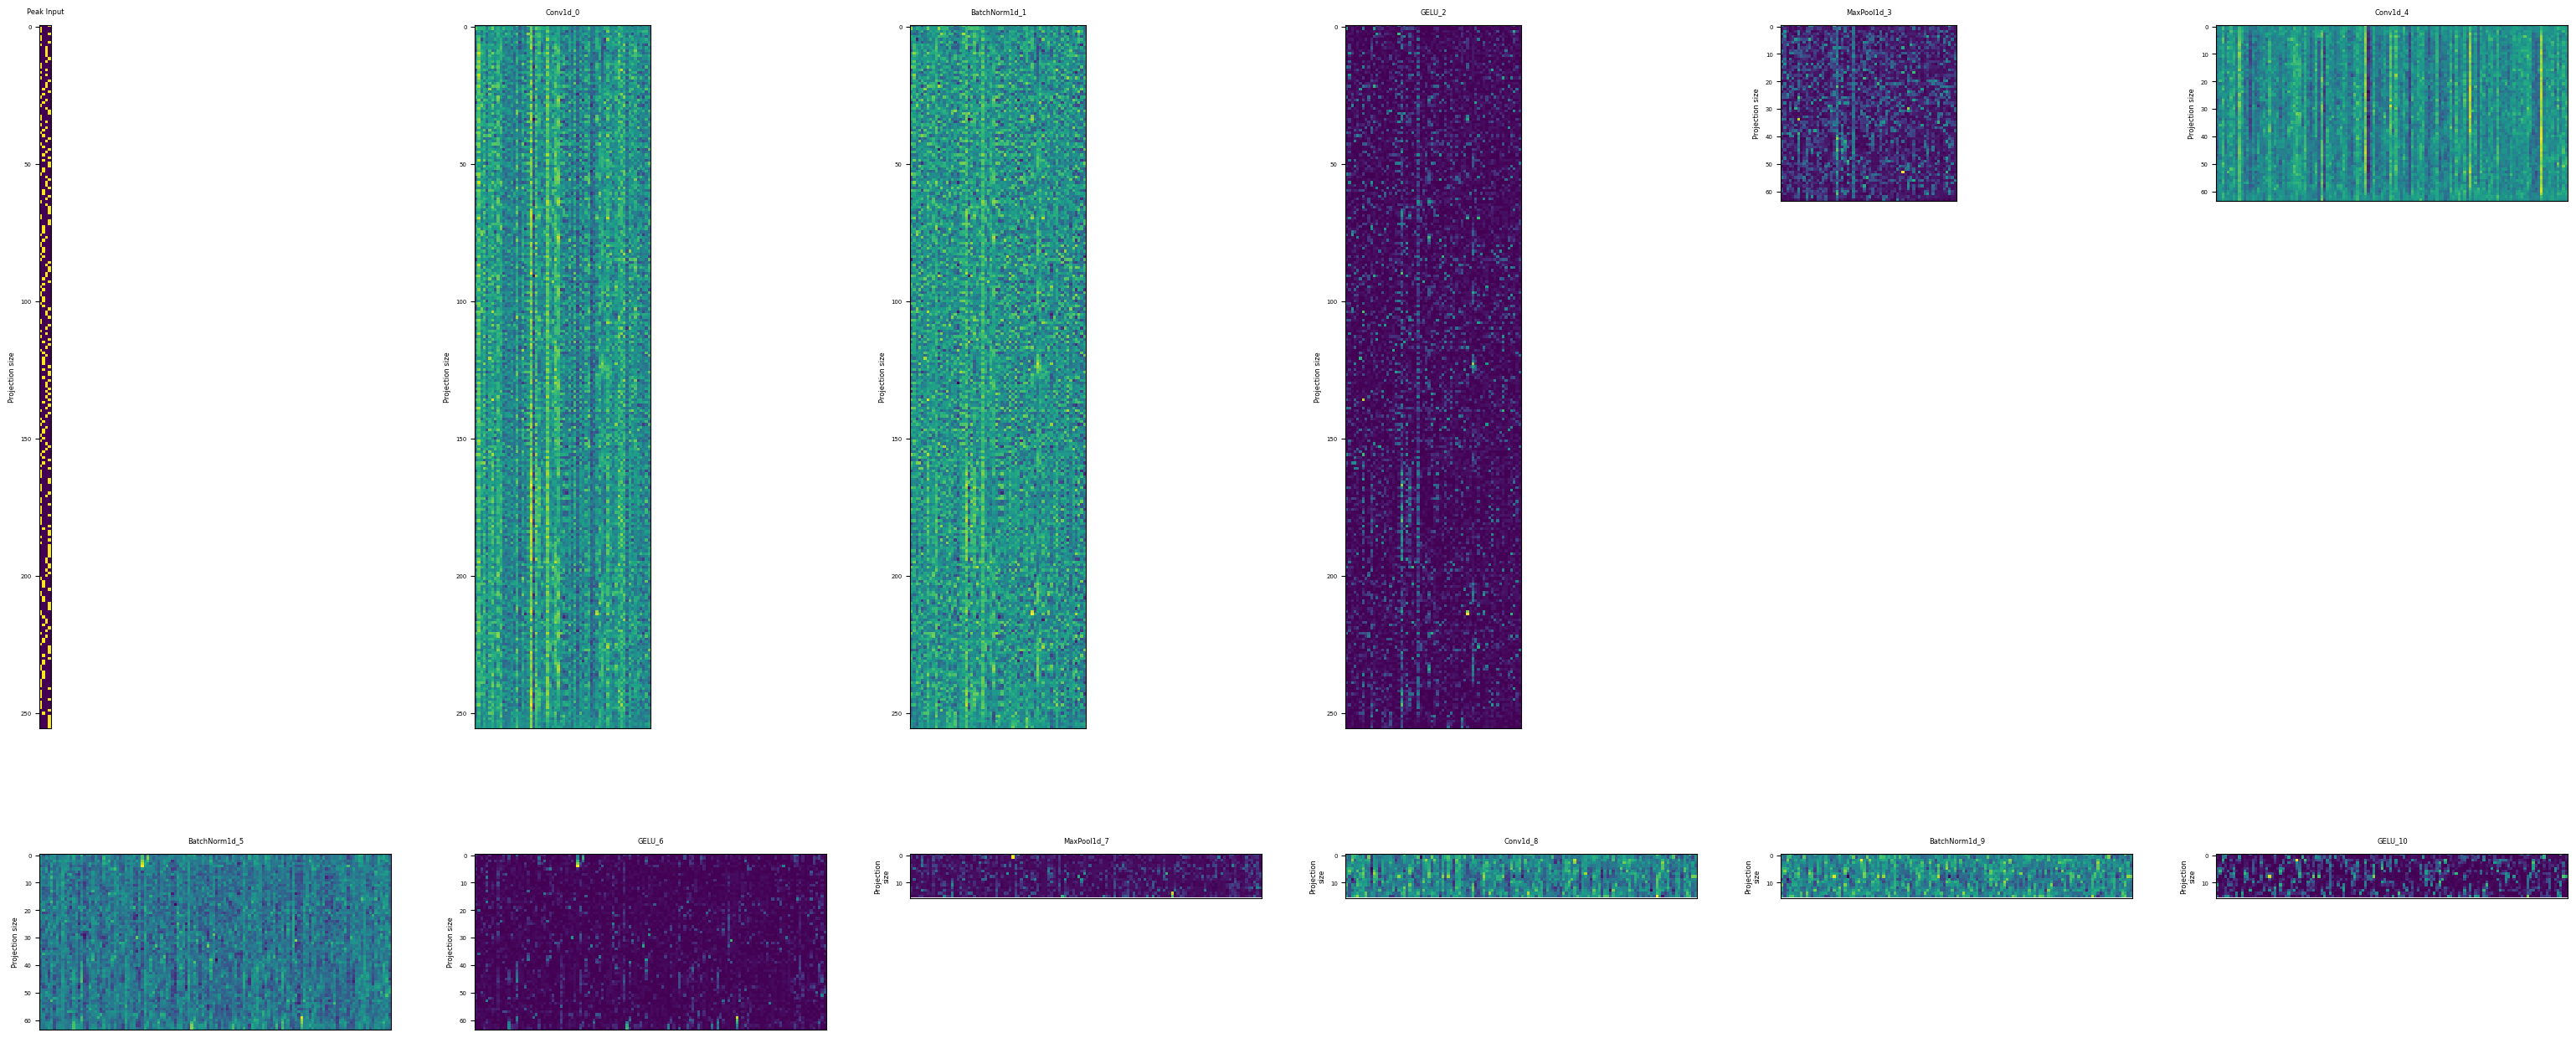

In [13]:
plot_projected_expression(
    peak_layer_dict,
    keep_square=False,
    height=14,
    ncols=6
)

### Cross Attention

In [21]:
tf_cross_input = tf_encoder_linear2
peak_cross_input = peak_encoder_output.transpose(1, 2)

peak_mask = torch.ones(
    peak_cross_input.shape[:2],
    dtype=torch.bool,
    device=peak_cross_input.device,
)

In [22]:
tf_dna_model.model.cross_attn.layers[0][1][0]

RMSNorm((128,), eps=None, elementwise_affine=True)

In [23]:
import torch

cross_attn = tf_dna_model.model.cross_attn
cross_layer_dict = {}
handles = []

def snapshot(output):
    """Store detached copies, preserving tuples/lists/dictionaries."""
    if isinstance(output, torch.Tensor):
        return output.detach().clone()
    if isinstance(output, tuple):
        return tuple(snapshot(value) for value in output)
    if isinstance(output, list):
        return [snapshot(value) for value in output]
    if isinstance(output, dict):
        return {key: snapshot(value) for key, value in output.items()}
    return output


def make_hook(name):
    def hook(module, inputs, output):
        cross_layer_dict[name] = snapshot(output)
    return hook


# Register hooks on each layer and all modules inside it.
for layer_num, layer in enumerate(cross_attn.layers):
    for module_name, module in layer.named_modules():
        name = f"CrossAttention_{layer_num}"
        if module_name:
            name += f"_{module_name.replace('.', '_')}"

        handles.append(
            module.register_forward_hook(make_hook(name))
        )

try:
    with torch.no_grad():
        # Use the same forward call and arguments as your normal execution.
        output = cross_attn(
            tf_cross_input,
            peak_cross_input,
            m,
            peak_mask,
        )
finally:
    # Remove hooks even if the forward pass raises an error.
    for handle in handles:
        handle.remove()

In [24]:
for name, output in cross_layer_dict.items():
    if isinstance(output, torch.Tensor):
        print(f"{name}: {output.shape}")
    elif isinstance(output, tuple):
        print(f"{name}: {[o.shape if isinstance(o, torch.Tensor) else type(o) for o in output]}")
    else:
        print(f"{name}: {type(output)}")

CrossAttention_0_0_norm: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_norm: torch.Size([1, 16, 128])
CrossAttention_0_0_to_qk: torch.Size([1, 5588, 128])
CrossAttention_0_0_to_v: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_qk: torch.Size([1, 16, 128])
CrossAttention_0_0_context_to_v: torch.Size([1, 16, 128])
CrossAttention_0_0_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_to_out: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_out: torch.Size([1, 16, 128])
CrossAttention_0_0: [torch.Size([1, 5588, 128]), torch.Size([1, 16, 128])]
CrossAttention_0_1_0: torch.Size([1, 5588, 128])
CrossAttention_0_1_1: torch.Size([1, 5588, 512])
CrossAttention_0_1_2: torch.Size([1, 5588, 512])
CrossAttention_0_1_3: torch.Size([1, 5588, 128])
CrossAttention_0_1: torch.S

In [25]:
def make_cross_attention_heatmaps(
    outputs,
    tf_mask,
    peak_mask,
    batch_index=0,
):
    heatmaps = {}

    # Select masks for one batch item.
    tf_valid = tf_mask[batch_index].detach().cpu().bool()
    peak_valid = peak_mask[batch_index].detach().cpu().bool()

    def add_output(name, output):
        # Handle modules returning multiple outputs.
        if isinstance(output, (tuple, list)):
            for index, value in enumerate(output):
                add_output(f"{name}_output_{index}", value)
            return

        if not isinstance(output, torch.Tensor):
            return

        tensor = output.detach().float().cpu()

        # Token features: (batch, tokens, features)
        if tensor.ndim == 3:
            matrix = tensor[batch_index]

            # Infer the token type from its length.
            # This works for your distinct TF/peak lengths: 5588 and 16.
            if matrix.shape[0] == len(tf_valid):
                matrix = matrix[tf_valid]
            elif matrix.shape[0] == len(peak_valid):
                matrix = matrix[peak_valid]
            else:
                raise ValueError(
                    f"{name}: cannot identify token dimension "
                    f"for shape {tuple(tensor.shape)}"
                )

            if matrix.shape[0] > 0:
                heatmaps[name] = (matrix.numpy(), None)

        # Attention: (batch, heads, TF tokens, peak tokens)
        elif tensor.ndim == 4:
            if tensor.shape[2:] != (len(tf_valid), len(peak_valid)):
                raise ValueError(
                    f"{name}: unexpected attention shape "
                    f"{tuple(tensor.shape)}"
                )

            attention = tensor[batch_index]
            attention = attention[:, tf_valid, :]
            attention = attention[:, :, peak_valid]

            for head_index, matrix in enumerate(attention):
                if all(size > 0 for size in matrix.shape):
                    heatmaps[f"{name}_head_{head_index}"] = (
                        matrix.numpy(),
                        None,
                    )

    for name, output in outputs.items():
        add_output(name, output)

    return heatmaps

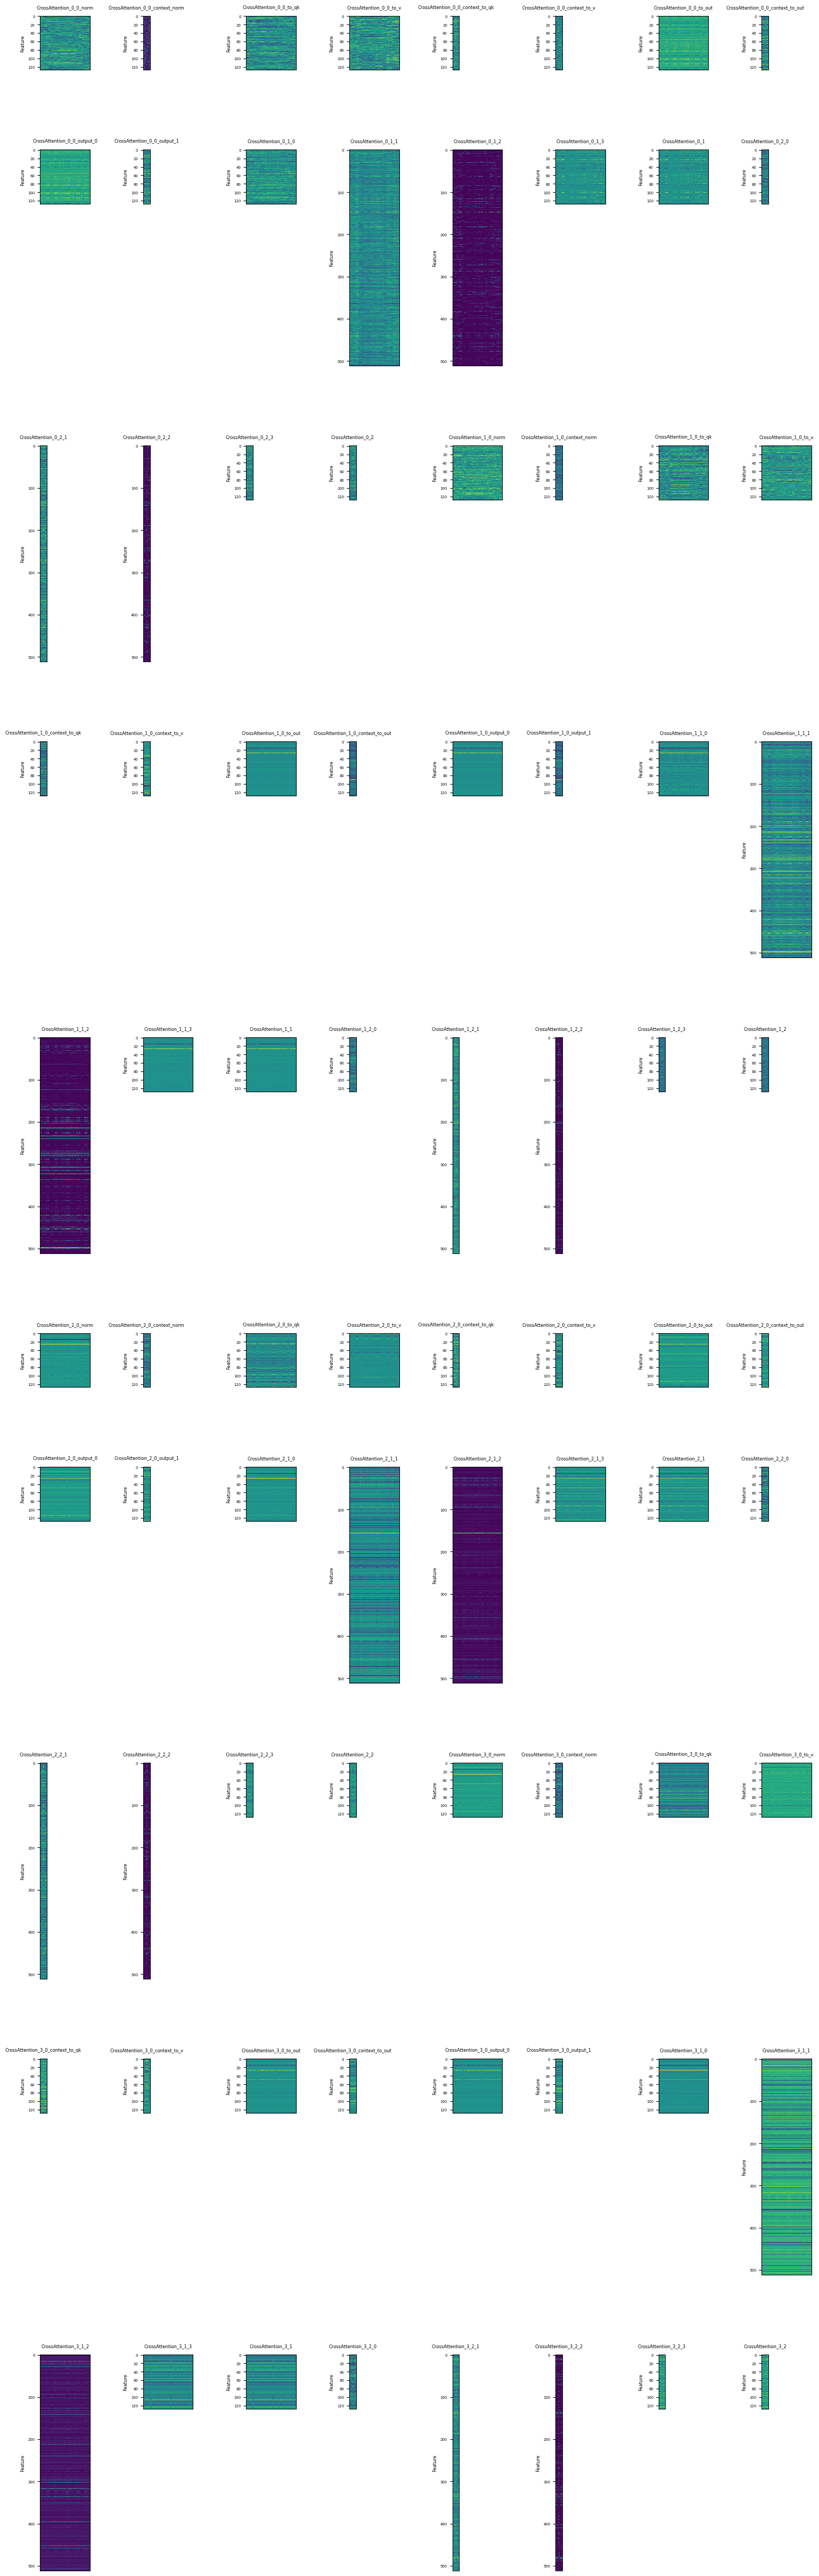

In [26]:
selected = {
    name: output
    for name, output in cross_layer_dict.items()
    if name.startswith("CrossAttention_")
}

heatmaps = make_cross_attention_heatmaps(
    selected,
    tf_mask=m,
    peak_mask=peak_mask,
)

# Plot feature outputs separately from attention matrices.
feature_heatmaps = {
    name: value
    for name, value in heatmaps.items()
    if "_head_" not in name
}

plot_projected_expression(
    feature_heatmaps,
    ncols=8,
    height=50,
    xlabel=None,
    ylabel="Feature",
)

### Full Model Flow

In [35]:
STREAM_COLORS = {
    "TF": "#1f77b4",
    "Peak": "#d62728",
    "Attention": "#9467bd",
    "Joint": "#444444",
}


def describe_module(module):
    """Short module name with its weight shape, e.g. 'Linear 128→512'."""
    name = type(module).__name__
    if isinstance(module, nn.Linear):
        return f"{name} {module.in_features}→{module.out_features}"
    if isinstance(module, nn.Conv1d):
        return f"{name} {module.in_channels}→{module.out_channels}, k={module.kernel_size[0]}"
    return name


def capture_model_flow(model, tf_embedding, tf_mask, peak_embedding):
    """
    Run one forward pass and record each intermediate output in execution order.

    tf_embedding:   [1, tf_len, 128]
    tf_mask:        [1, tf_len], True for real TF tokens
    peak_embedding: [1, 256, 4] one-hot DNA

    Returns a list of dicts with keys:
        label:  "<block> · <stage>"
        stream: "TF", "Peak", "Attention", or "Joint"
        matrix: 2D array, rows = features, columns = positions
        groups: number of attention heads stacked in the rows, else None

    Forward hooks fire in the order the modules run, so the list follows the
    real forward pass. The residual sums between blocks are not modules, so
    they are rebuilt from each block's input and output.

    The model runs in eval mode, so Dropout is the identity and BatchNorm uses
    its running statistics. Dropout layers are therefore not recorded, except
    the two in the attention block, whose outputs are the attention weights.
    """
    net = getattr(model, "model", model)
    device = next(net.parameters()).device

    tf_embedding = tf_embedding.to(device=device, dtype=torch.float32)
    tf_mask = tf_mask.to(device).bool()
    peak_embedding = peak_embedding.to(device=device, dtype=torch.float32)

    tf_valid = tf_mask[0].cpu()
    records = []
    handles = []

    def to_matrix(tensor, stream, layout):
        values = tensor.detach().float().cpu()[0]

        if layout == "tokens":
            # [tokens, features] -> [features, tokens], without TF padding
            if stream == "TF":
                values = values[tf_valid]
            values = values.T
        elif layout == "attention":
            # [heads, TF tokens, peak tokens] -> [heads * peak tokens, TF tokens]
            values = values[:, tf_valid, :].transpose(1, 2)
            values = values.reshape(-1, values.shape[-1])
        elif layout == "vector":
            values = values.reshape(1, -1)
        # The "channels" layout is already [channels, positions]

        return values.numpy()

    def add(label, stream, layout, tensor, groups=None):
        records.append({
            "label": label,
            "stream": stream,
            "matrix": to_matrix(tensor, stream, layout),
            "groups": groups,
        })

    def watch_output(module, label, stream, layout, groups=None):
        def hook(module, inputs, output):
            add(label, stream, layout, output, groups)
        handles.append(module.register_forward_hook(hook))

    def watch_input(module, label, stream, layout):
        def hook(module, inputs):
            add(label, stream, layout, inputs[0])
        handles.append(module.register_forward_pre_hook(hook))

    # Encoders
    watch_input(net.tf_encoder[0], "TF embedding input", "TF", "tokens")
    for module in net.tf_encoder:
        if not isinstance(module, nn.Dropout):
            watch_output(module, f"TF encoder · {describe_module(module)}", "TF", "tokens")

    watch_input(net.peak_encoder[0], "Peak one-hot input", "Peak", "channels")
    for module in net.peak_encoder:
        watch_output(module, f"Peak encoder · {describe_module(module)}", "Peak", "channels")

    # Cross-attention layers
    for layer_num, (attn, ff, context_ff) in enumerate(net.cross_attn.layers):
        block = f"Cross-attn {layer_num}"

        for module, name, stream in [
            (attn.norm, "RMSNorm", "TF"),
            (attn.context_norm, "RMSNorm", "Peak"),
            (attn.to_qk, "query/key", "TF"),
            (attn.to_v, "value", "TF"),
            (attn.context_to_qk, "query/key", "Peak"),
            (attn.context_to_v, "value", "Peak"),
        ]:
            watch_output(module, f"{block} · {stream} {name}", stream, "tokens")

        # Each TF token's weights over peak tokens (columns sum to 1 per head),
        # then each peak token's weights over TF tokens (rows sum to 1).
        watch_output(attn.dropout, f"{block} · TF reads peak", "Attention", "attention", attn.heads)
        watch_output(attn.context_dropout, f"{block} · Peak reads TF", "Attention", "attention", attn.heads)

        watch_output(attn.to_out, f"{block} · TF attention output", "TF", "tokens")
        watch_output(attn.context_to_out, f"{block} · Peak attention output", "Peak", "tokens")

        def attention_residual_hook(module, inputs, output, block=block):
            (x, context), (x_out, context_out) = inputs, output
            add(f"{block} · TF residual + attention", "TF", "tokens", x + x_out)
            add(f"{block} · Peak residual + attention", "Peak", "tokens", context + context_out)
        handles.append(attn.register_forward_hook(attention_residual_hook))

        for stream, feedforward in (("TF", ff), ("Peak", context_ff)):
            for module in feedforward:
                watch_output(module, f"{block} · {stream} FF {describe_module(module)}", stream, "tokens")

            def ff_residual_hook(module, inputs, output, block=block, stream=stream):
                add(f"{block} · {stream} residual + FF", stream, "tokens", inputs[0] + output)
            handles.append(feedforward.register_forward_hook(ff_residual_hook))

    watch_output(net.cross_attn.norm, "Final RMSNorm · TF", "TF", "tokens")
    watch_output(net.cross_attn.context_norm, "Final RMSNorm · Peak", "Peak", "tokens")

    # The classifier input is [TF mean pool, peak mean pool]
    def pooled_hook(module, inputs):
        tf_pooled, peak_pooled = inputs[0].chunk(2, dim=-1)
        add("Mean pool · TF", "TF", "vector", tf_pooled)
        add("Mean pool · Peak", "Peak", "vector", peak_pooled)
    handles.append(net.classifier[0].register_forward_pre_hook(pooled_hook))

    for module in net.classifier:
        if not isinstance(module, nn.Dropout):
            watch_output(module, f"Classifier · {describe_module(module)}", "Joint", "vector")

    was_training = net.training
    net.eval()
    try:
        with torch.no_grad():
            net(tf_embedding, tf_mask, peak_embedding)
    finally:
        # Remove hooks and restore the mode even if the forward pass fails.
        for handle in handles:
            handle.remove()
        net.train(was_training)

    return records


def color_range(matrix, robust):
    """Color scale limits for one heatmap: the 2nd-98th percentiles if robust, else min-max."""
    if robust:
        low, high = np.percentile(matrix, [2, 98])
    else:
        low, high = matrix.min(), matrix.max()
    if high <= low:
        high = low + 1e-6  # Constant heatmaps, such as the 1 x 1 logit
    return low, high


def block_mean(matrix, max_cells):
    """Average blocks of rows and columns so neither axis exceeds max_cells."""
    # Small planes, such as the one-hot DNA input, keep their exact values
    if not max_cells or matrix.size <= max_cells ** 2:
        return matrix

    for axis in (0, 1):
        n = matrix.shape[axis]
        if max_cells and n > max_cells:
            starts = np.linspace(0, n, max_cells + 1).astype(int)
            counts = np.diff(starts)
            sums = np.add.reduceat(matrix, starts[:-1], axis=axis)
            matrix = sums / (counts[:, None] if axis == 0 else counts[None, :])
    return matrix


# Left and right arrow keys move the slider one step.
SLIDER_ARROW_KEYS_JS = """
var gd = document.getElementById('{plot_id}');
document.addEventListener('keydown', function (event) {
    if (event.key !== 'ArrowLeft' && event.key !== 'ArrowRight') return;
    var slider = gd.layout.sliders[0];
    var next = slider.active + (event.key === 'ArrowRight' ? 1 : -1);
    if (next < 0 || next >= slider.steps.length) return;
    var args = slider.steps[next].args;
    var layoutUpdate = Object.assign({'sliders[0].active': next}, args[1]);
    Plotly.update(gd, args[0], layoutUpdate, args[2]);
});
"""


def plot_model_flow(
    records,
    output_path,
    title=None,
    max_cells=64,
    z_scale=3.0,
    colorscale="Viridis",
    robust=True,
    faded_opacity=0.1,
):
    """
    Stack the heatmaps from capture_model_flow along z in execution order and
    write the figure to a standalone HTML file at output_path.

    Each stage is a flat plane with one unit per element: its x size is the
    number of columns (positions) and its y size is the number of rows
    (features). All planes start at the origin, so the x and y axes read as
    element counts. z is the processing order, with extra space where a new
    block starts. z_scale sets the stack height relative to the largest
    plane side.

    A slider under the plot steps through the stages. At each step, the
    selected stage is opaque, the stages before it have faded_opacity, and
    the stages after it are hidden. The first step, "All", shows the full
    stack. The left and right arrow keys also move the slider.

    Planes with more than max_cells ** 2 elements are block-averaged to at most
    max_cells cells per axis, to keep the file small. Smaller planes, such as
    the one-hot DNA input, are drawn exactly. Every plane keeps its true size.
    None draws every element.

    Each plane has its own color scale. robust=True clips it to the 2nd-98th
    percentiles, so a few large features do not hide the rest.
    Hover shows the stage, its shape, and the cell value. Click a stream in
    the legend to hide or show it. "Stage labels" adds a label to each plane.

    The HTML embeds plotly.js, so it opens without an internet connection.
    Returns output_path.
    """
    if not records:
        raise ValueError("records must not be empty")

    n_stages = len(records)

    # One z level per stage, plus extra space where a new block starts
    blocks = [record["label"].split(" · ")[0] for record in records]
    steps = [0] + [
        1 + (2 if blocks[i] != blocks[i - 1] else 0)
        for i in range(1, n_stages)
    ]
    z_levels = np.cumsum(steps).astype(float)

    max_rows = max(record["matrix"].shape[0] for record in records)
    max_cols = max(record["matrix"].shape[1] for record in records)
    longest = max(max_rows, max_cols)

    # Each stage adds two traces, its plane and its outline, so the slider
    # can fade or hide them together: stage i owns traces 2i and 2i + 1.
    fig = go.Figure()
    in_legend = set()

    for record, z in zip(records, z_levels):
        matrix = record["matrix"]
        rows, cols = matrix.shape
        stream = record["stream"]

        cmin, cmax = color_range(matrix, robust)
        shown = block_mean(matrix, max_cells)

        # Repeat the inner cell edges and the values, so each cell is a flat
        # square of one color instead of a gradient between cell centers.
        x = np.repeat(np.linspace(0, cols, shown.shape[1] + 1), 2)[1:-1]
        y = np.repeat(np.linspace(0, rows, shown.shape[0] + 1), 2)[1:-1]
        color = np.repeat(np.repeat(shown, 2, axis=0), 2, axis=1).astype(np.float32)

        hover = f"<b>{record['label']}</b><br>{rows} × {cols}"
        if shown.shape != matrix.shape:
            hover += f", shown as {shown.shape[0]} × {shown.shape[1]} block means"

        fig.add_trace(go.Surface(
            x=x,
            y=y,
            z=np.full(color.shape, z, dtype=np.float32),
            surfacecolor=color,
            customdata=color,  # Surface hover cannot read surfacecolor
            cmin=cmin,
            cmax=cmax,
            colorscale=colorscale,
            showscale=False,
            # Flat lighting, so the colors are not shaded
            lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0, fresnel=0.0),
            name=record["label"],
            legendgroup=stream,
            hovertemplate=hover + "<br>value %{customdata:.3g}<extra></extra>",
        ))

        # Plane border, plus a line between attention heads
        outline_x = [0, cols, cols, 0, 0]
        outline_y = [0, 0, rows, rows, 0]
        if record["groups"]:
            for boundary in np.arange(1, record["groups"]) * rows / record["groups"]:
                outline_x += [None, 0, cols]
                outline_y += [None, boundary, boundary]

        # The first outline of each stream is its legend entry. Clicking it
        # hides the whole stream, because all its traces share a legend group.
        fig.add_trace(go.Scatter3d(
            x=outline_x,
            y=outline_y,
            z=[None if value is None else z for value in outline_x],
            mode="lines",
            line=dict(color=STREAM_COLORS[stream], width=3),
            name="Classifier" if stream == "Joint" else stream,
            legendgroup=stream,
            showlegend=stream not in in_legend,
            hoverinfo="skip",
        ))
        in_legend.add(stream)

    fig.add_trace(go.Scatter3d(
        x=np.zeros(n_stages),
        y=np.zeros(n_stages),
        z=z_levels,
        mode="text",
        text=[record["label"] for record in records],
        textposition="middle left",
        textfont=dict(
            color=[STREAM_COLORS[record["stream"]] for record in records],
            size=10,
        ),
        name="Stage labels",
        visible="legendonly",  # Readable once zoomed in
        hoverinfo="skip",
    ))

    def slider_step(selected):
        """Show every stage (selected=None), or focus on one stage."""
        opacity, visible, hoverinfo = [], [], []
        for i in range(n_stages):
            if selected is None or i == selected:
                stage_opacity, stage_visible, stage_hover = 1.0, True, "all"
            elif i < selected:
                stage_opacity, stage_visible, stage_hover = faded_opacity, True, "skip"
            else:
                stage_opacity, stage_visible, stage_hover = 1.0, False, "skip"

            # Plane, then outline. Faded planes do not take the hover.
            opacity += [stage_opacity, stage_opacity]
            visible += [stage_visible, stage_visible]
            hoverinfo += [stage_hover, "skip"]

        if selected is None:
            subtitle = f"All {n_stages} stages"
        else:
            rows, cols = records[selected]["matrix"].shape
            subtitle = f"Stage {selected + 1}/{n_stages}: {records[selected]['label']} ({rows} × {cols})"

        return dict(
            method="update",
            label="All" if selected is None else "",
            value="all" if selected is None else str(selected),
            args=[
                {"opacity": opacity, "visible": visible, "hoverinfo": hoverinfo},
                {"title.text": f"{title}<br><sup>{subtitle}</sup>" if title else subtitle},
                list(range(2 * n_stages)),
            ],
        )

    slider_steps = [slider_step(None)] + [slider_step(i) for i in range(n_stages)]

    block_starts = [i for i in range(n_stages) if i == 0 or blocks[i] != blocks[i - 1]]

    fig.update_layout(
        title=slider_steps[0]["args"][1]["title.text"],
        margin=dict(l=0, r=0, t=70, b=70),
        # Keep the camera when the slider changes the traces
        uirevision="model-flow",
        sliders=[dict(
            active=0,
            steps=slider_steps,
            currentvalue=dict(visible=False),  # The title names the stage
            x=0.05,
            len=0.9,
            pad=dict(t=0, b=10),
        )],
        scene=dict(
            xaxis=dict(title="Columns (positions)", range=[0, max_cols]),
            yaxis=dict(title="Rows (features)", range=[0, max_rows]),
            zaxis=dict(
                title="",
                # Fixed range, so hiding later stages does not rescale the plot
                range=[z_levels[0] - 1, z_levels[-1] + 1],
                tickvals=[z_levels[i] for i in block_starts],
                ticktext=[blocks[i] for i in block_starts],
            ),
            aspectmode="manual",
            aspectratio=dict(x=max_cols / longest, y=max_rows / longest, z=z_scale),
            camera=dict(eye=dict(x=1.6, y=-1.6, z=0.6)),
        ),
    )

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.write_html(
        output_path,
        include_plotlyjs=True,
        default_height="100vh",
        post_script=SLIDER_ARROW_KEYS_JS,
    )
    logging.info(f"Saved {output_path} ({output_path.stat().st_size / 1e6:.1f} MB)")

    return output_path


def stage_file_stem(stage_number, label):
    """File name for one stage, e.g. (25, 'Cross-attn 0 · TF attention output')
    -> '025_Cross-attn_0_TF_attention_output'."""
    name = label.replace("→", "to").replace("+", "plus").replace("/", "-").replace("=", "")
    name = re.sub(r"[^A-Za-z0-9-]+", "_", name).strip("_")
    return f"{stage_number:03d}_{name}"


def save_flow_heatmaps(records, output_dir, cell_size=2.0, cmap="viridis", robust=True):
    """
    Save each stage from capture_model_flow as its own SVG heatmap in
    output_dir, with no title, axes, ticks, or colorbar.

    Every element is a cell_size x cell_size point square, so all the images
    share one scale: a 512-feature layer is 4 times taller than a 128-feature
    layer. Every element is drawn; nothing is block-averaged. The SVG embeds
    the matrix at one image pixel per element and tells viewers not to smooth
    it, so the cells stay sharp at any zoom.

    Each heatmap has its own color scale, the same as in plot_model_flow.

    File names start with the 1-based stage number, which is also the stage
    number on the plot_model_flow slider, e.g.
    025_Cross-attn_0_TF_attention_output.svg. Returns output_dir.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    for stage_number, record in enumerate(records, start=1):
        matrix = record["matrix"]
        rows, cols = matrix.shape
        vmin, vmax = color_range(matrix, robust)

        # The axes fill the whole figure, and the figure is cell_size points
        # per element, so the heatmap has no border or padding.
        fig = plt.figure(figsize=(cols * cell_size / 72, rows * cell_size / 72))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")
        fig.patch.set_visible(False)  # No background box
        image = ax.imshow(
            matrix,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
            interpolation="none",  # Embed the matrix unresampled
        )
        image.set_clip_on(False)  # No clip path around the image

        fig.savefig(output_dir / f"{stage_file_stem(stage_number, record['label'])}.svg")
        plt.close(fig)

    logging.info(f"Saved {len(records)} SVG heatmaps to {output_dir}")

    return output_dir

In [ ]:
dataset_item_num = 4

tf_idx = int(dataset[dataset_item_num]["tf_idx"])
peak_idx = int(dataset[dataset_item_num]["peak_idx"])

tf_embedding = tf_embeddings_tensor[dataset[dataset_item_num]["tf_idx"]].unsqueeze(0).to(device=device, dtype=dtype)
tf_mask = tf_mask_tensor[dataset[dataset_item_num]["tf_idx"]].unsqueeze(0).to(device=device, dtype=torch.bool)
peak_onehot = one_hot_peaks[dataset[dataset_item_num]["peak_idx"]].unsqueeze(0).to(device=device, dtype=dtype)

tf_names = pd.read_csv(tf_dna_input_cache_dir / "tf_name_to_idx.csv").set_index("tf_idx")["tf_name"]
tf_name = tf_names[tf_idx]

flow = capture_model_flow(
    tf_dna_model,
    tf_embedding=tf_embedding,
    tf_mask=tf_mask,
    peak_embedding=peak_onehot,
)

logit = flow[-1]["matrix"].item()
probability = 1 / (1 + np.exp(-logit))

print(f"{len(flow)} stages, logit {logit:.3f}, binding probability {probability:.3f}")

output_path = PROJECT_DIR / "new_plots" / "model_flow" / f"model_flow_{species}_{tf_name}_peak{peak_idx}.html"

plot_model_flow(
    flow,
    output_path=output_path,
    title=f"{tf_name} × peak {peak_idx} ({species}) · logit {logit:.2f}, binding probability {probability:.3f}",
)

# One SVG per stage, in a folder named after the HTML file
save_flow_heatmaps(flow, output_dir=output_path.with_suffix(""))

113 stages, logit 3.076, binding probability 0.956


2026-10-15 10:47:01 - INFO - Saved /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383.html (29.5 MB)
2026-10-15 10:47:04 - INFO - Saved 113 SVG heatmaps to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383


PosixPath('/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_flow/model_flow_mm10_Cebpb_peak1463383')